# 12. 수식 없이도 이해할 수 있는 ChatGPT와 Stable Diffusion [프로젝트]
---
지금까지는 Stable Diffusion 모델만을 이용하여 이미지를 생성하거나 이미지의 스타일을 바꾸는 실습을 해보다. 이번에는 여기서 조금 더 나아가서 ControlNet을 사용하여 이미지에 조건을 주어 이미지를 다양하게 변형해보자.

### ControlNet이란?
---
Stable Diffusion은 텍스트 프롬프트 또는 입력 이미지를 통하여 이미지를 생성하지만 생성된 이미지를 원하는 대로 출력하기 어렵다. 아무리 프롬프트를 자세하게 써도 생성되는 이미지가 내가 원하는 자세, 구도, 배경을 갖도록 하는 것은 거의 불가능하다. ControlNet은 Diffusion 모델에 추가 조건을 추가하여 출력되는 이미지를 쉽게 제어할 수 있다. 뿐만 아니라 ControlNet은 훈련 데이터가 작아도 학습이 잘 되고 빠르다는 장점이 있어 개인용 기기에서 사용할 수 있다는 장점이 있다.

ControlNet은 논문 ['Adding Conditional Control to Text-to-Image Diffusion Models'](https://arxiv.org/abs/2302.05543)에서 소개되었고, 외곽선 감지(Canny Edge detection), 인체 자세 감지(Human pose), 낙서 지도(Scribble map), 시맨틱 세그멘테이션(Semantic segmentation) 등 다양한 전처리기(Preprocessor)를 Stable Diffusion 모델에 도입할 수 있다. 그래서 원하는 자세, 구도 등으로 이미지를 생성할 수 있다.

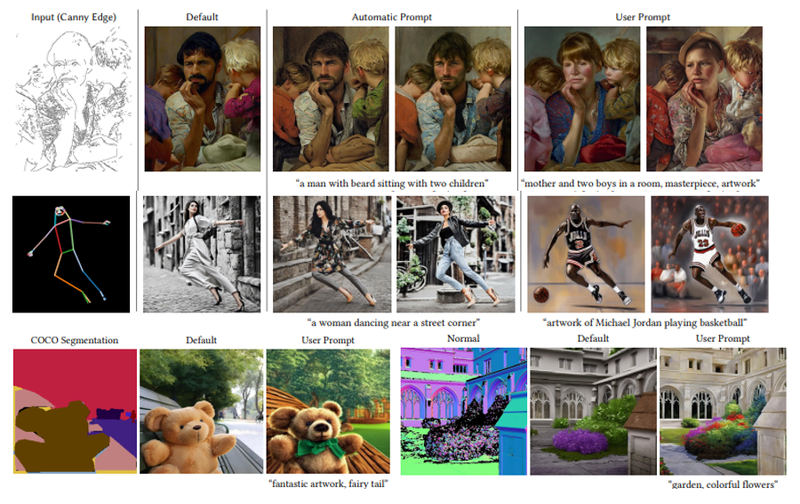

ControlNet의 원리나 구조도 중요하지만 그건 추후에 개인적으로 공부하기로 하고, 여기서는 ControlNet을 사용하여 이미지를 어떻게 제어할 수 있는지를 프로젝트를 통해 알아보자. 😁

> 이번 프로젝트는 허깅페이스에서 제공하는 [실습 코드](https://huggingface.co/docs/diffusers/v0.17.1/en/api/pipelines/stable_diffusion/overview)를 수정 및 재구성하였습니다.

In [1]:
# 필요한 라이브러리를 설치
# Stable Diffusion 설치
!pip install --upgrade -qq git+https://github.com/huggingface/diffusers.git transformers accelerate
    
# !pip install: Jupyter Notebook이나 셀 스크립트에서 파이썬 패키지를 설치하기 위한 pip 명령어를 실행하는 부분
# --upgrade: 설치된 패키지를 최신 버전으로 업그레이드하는 옵션
# -qq: 조용한(quiet) 모드로 설치를 진행하도록 하는 옵션으로, 출력 메시지를 최소화
# git+https://github.com/huggingface/diffusers.git: diffusers 라이브러리를 GitHub 저장소에서 직접 설치하도록 지정한 부분이다. 
# git+는 Git 저장소에서 직접 설치하겠다는 의미
# transformers: Hugging Face에서 제공하는 transformers 라이브러리를 설치(이 라이브러리는 자연어 처리 모델들을 제공하고 관리하는 역할)
# accelerate: Hugging Face에서 제공하는 accelerate 라이브러리를 설치(이 라이브러리는 PyTorch나 TensorFlow와 같은 딥러닝 라이브러리를 가속화하기 위한 도구를 제공)

# 이 코드는 주어진 라이브러리들을 최신 버전으로 업그레이드하여 설치하는 명령어
# 특히 diffusers 라이브러리는 안정적인 디퓨전(Stable Diffusion)을 사용한 이미지 생성을 위한 라이브러리

이미지를 생성하다 보면 `CUDA out of memery`가 나올 때가 있다. 그럴 때는 아래 코드의 주석을 풀고 사용하자.

In [2]:
# 메모리 삭제
# torch.cuda.empty_cache()

### 윤곽선 검출
---
윤곽선을 검출해 보자. ControlNet은 다양한 윤곽선 검출 알고리즘을 제공하지만 우리는 가장 유명하고 효과적인 윤곽선 검출 알고리즘인 Canny 알고리즘을 사용할 것이다.

먼저 이미지를 불러온다. 누구나 익히 아는 이미지를 사용할 것이다.

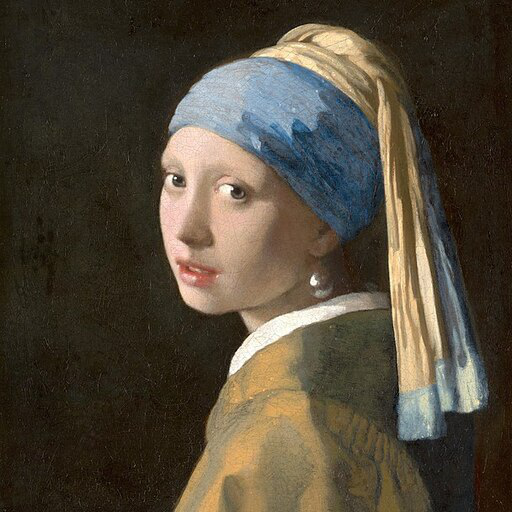

In [3]:
import torch # PyTorch 라이브러리를 불러온다
from diffusers import StableDiffusionControlNetPipeline # diffusers 라이브러리에서 StableDiffusionControlNetPipeline 클래스를 불러온다
                                                        # 이 클래스는 안정적인 디퓨전을 이용한 이미지 생성을 수행하는 파이프라인을 제공
from diffusers.utils import load_image # diffusers 라이브러리의 load_image 함수를 불러온다(주어진 URL에서 이미지를 로드하는데 사용)

# 이미지 불러오기 - 주어진 URL에서 이미지를 로드하여 image 변수에 저장
image = load_image( # load_image 함수는 URL에서 이미지를 가져와 PyTorch의 텐서 형태로 변환
    "https://hf.co/datasets/huggingface/documentation-images/resolve/main/diffusers/input_image_vermeer.png"
)

image # 불러온 이미지 출력

OpenCV를 사용하여 이미지의 윤곽선을 검출한다.

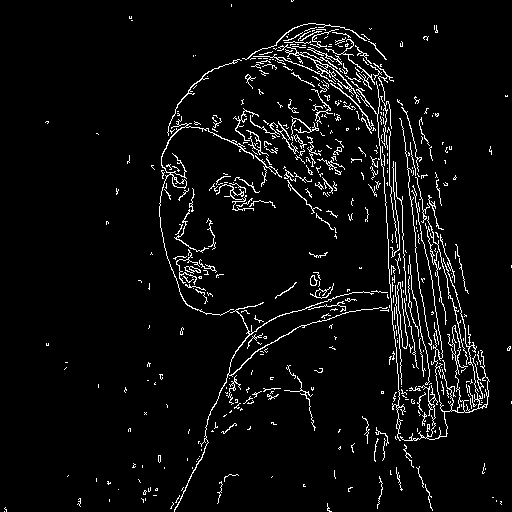

In [4]:
# 이미지에 캐니 에지 검출(Canny edge detection)을 적용
import cv2
from PIL import Image 
import numpy as np

# 이미지를 NumPy 배열로 변환합니다. 
image = np.array(image) # Pillow의 Image 객체인 image를 NumPy 배열로 변환, 
                        # 이로써 이미지에 대한 픽셀 데이터를 다루기 쉬운 NumPy 배열로 사용할 수 있다.

# Canny 에지 검출을 위해 사용되는 임계값(threshold)을 지정
#  에지 검출은 주어진 이미지에서 명암의 차이가 특정 임계값을 넘는 픽셀을 찾아서 에지로 간주
low_threshold = 100
high_threshold = 200

# 윤곽선을 검출합니다. 
image = cv2.Canny(image, low_threshold, high_threshold) # OpenCV의 cv2.Canny 함수를 사용하여 이미지에 Canny 에지 검출을 적용
image = image[:, :, None] # 에지를 검출한 이미지를 채널(channel) 수가 1인 이미지로 변경, 
                          # Canny 에지 검출은 흑백 이미지를 반환하므로, 이미지의 채널 수를 1로 만들어 준다.
image = np.concatenate([image, image, image], axis=2) # 이미지를 세 번 반복하여(RGB 채널을 만들기 위해) NumPy 배열로 합친다.
                                                      # 이렇게 함으로써 흑백 이미지를 RGB 이미지로 변환
canny_image = Image.fromarray(image)  # NumPy 배열을 PIL 이미지로 변환합니다.
                                      # NumPy 배열을 Pillow의 Image 객체로 변환, 
                                      # 이로써 캐니 에지가 적용된 이미지를 다루기 위해 Pillow의 기능을 활용할 수 있게됨

canny_image # 캐니 에지가 적용된 이미지를 출력

윤곽선 검출 전처리기를 사용한 모델 파이프라인을 불러오자.

In [5]:
# Canny 에지 검출을 수행하는 모델과 안정적인 디퓨전을 사용하는 이미지 생성 파이프라인을 통합하여 사용할 수 있게끔 설정하는 역할
# 결과적으로, 이 파이프라인은 안정적인 디퓨전을 기반으로 이미지를 생성하면서, 입력 이미지에 대해 Canny 에지를 반영
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel
# StableDiffusionControlNetPipeline은 안정적인 디퓨전을 이용한 이미지 생성을 위한 파이프라인을 정의
# ControlNetModel은 Canny 에지 검출을 수행하는 모델

# "lllyasviel/sd-controlnet-canny"로 미리 학습된 Canny 에지 검출 모델을 가져와서 canny_controlnet 변수에 할당
# 이 모델은 주어진 이미지에 대해 Canny 에지를 검출하는 역할
canny_controlnet = ControlNetModel.from_pretrained("lllyasviel/sd-controlnet-canny", torch_dtype=torch.float16) # 모델이 사용할 데이터 타입을 16비트 부동소수점으로 설정

# "runwayml/stable-diffusion-v1-5"로 미리 학습된 안정적인 디퓨전 파이프라인을 가져와서 canny_pipe 변수에 할당
canny_pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5", controlnet=canny_controlnet, torch_dtype=torch.float16 # controlnet=canny_controlnet은 Canny 에지 검출 모델을 파이프라인에 통합하는 역할
)                                                                                            #  파이프라인이 사용할 데이터 타입을 16비트 부동소수점으로 설정

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

윤곽선을 추출한 이미지에 프롬프트를 적용하여 새로운 이미지를 생성해 보겠다.

  0%|          | 0/20 [00:00<?, ?it/s]

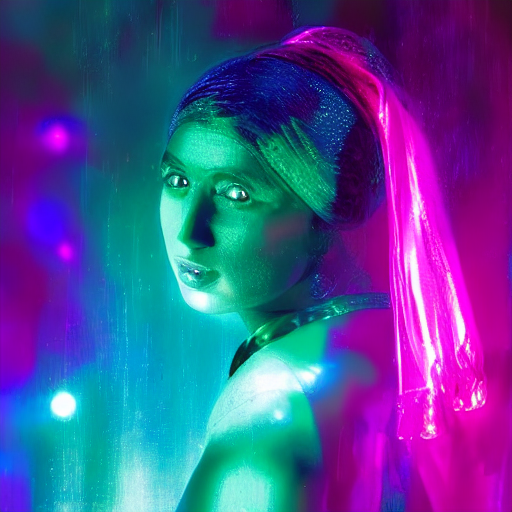

In [6]:
# 안정적인 디퓨전(Stable Diffusion)을 사용하여 Canny 에지를 적용한 이미지를 생성하고 저장
from diffusers import UniPCMultistepScheduler # diffusers 라이브러리에서 UniPCMultistepScheduler를 가져옴, 
                                              # UniPC(Uniform Perceptual Control) 기반의 다단계 스케줄러를 사용

# Canny 에지를 적용한 이미지 생성 파이프라인(canny_pipe)의 스케줄러를 UniPCMultistepScheduler로 설정    
canny_pipe.scheduler = UniPCMultistepScheduler.from_config(canny_pipe.scheduler.config) #  from_config 메서드를 사용하여 스케줄러의 설정(configuration)을 복사
canny_pipe = canny_pipe.to("cuda") # 생성된 파이프라인을 GPU("cuda")로 이동(이로써 이미지 생성을 GPU 가속화하여 빠르게 수행할 수 있다)

# 동일한 이미지를 생성하기 위해 seed를 지정합니다. 
generator = torch.manual_seed(0)  # 이미지 생성을 위한 난수 생성기를 초기화
                                  # torch.manual_seed(0)는 시드를 0으로 설정하여 동일한 이미지를 생성하기 위한 재현성을 확보

# 이미지를 생성합니다. 
canny_image = canny_pipe(
    prompt="disco dancer with colorful lights", 
    num_inference_steps=20, # 생성된 이미지에 대한 추론 단계의 수를 지정
    generator=generator, # 난수 생성기를 사용하여 이미지를 생성
    image=canny_image # 이전에 생성한 Canny 에지가 적용된 이미지를 입력으로 사용
).images[0]

# 생성된 이미지를 저장합니다. 
canny_image.save("/aiffel/aiffel/canny_image.png")  

# 생성된 이미지를 출력합니다. 
canny_image

프롬프트 외에도 부정적인 프롬프트(negative_propmt)를 넣을 수도 있고, 하이퍼파라미터를 조절할 수도 있다.

* `negative_propmt`: 원하지 않는 요소를 적을 수 있다.
* `controlnet_conditioning_scale`: ContorlNet으로 조건을 어느 정도 주느냐를 조절한다. Default는 1이고, 실수값으로 설정할 수 있다.
* `num_inference_steps`: 추론 횟수로, 값이 커질수록 고해상도 이미지가 출력되지만 출력되는 시간이 오래 걸린다. default 값은 50이다.
* `guidance_scale`: 얼마나 주어진 프롬프트에 근접한 이미지를 생성할지를 설정하는 하이퍼파라미터로, 값이 커질수록 문자열에 근접한 이미지가 생성되지만 이미지 품질이 떨어질 수 있다. default는 7.5이다.

프롬프트와 부정적인 프롬프트는 ChatGPT를 이용하여 생성해 보자. 직접 프롬프트를 작성하는 것보다 더 멋진 이미지를 생성할 수 있다.

Token indices sequence length is longer than the specified maximum sequence length for this model (80 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['fantasy realm.']


  0%|          | 0/40 [00:00<?, ?it/s]

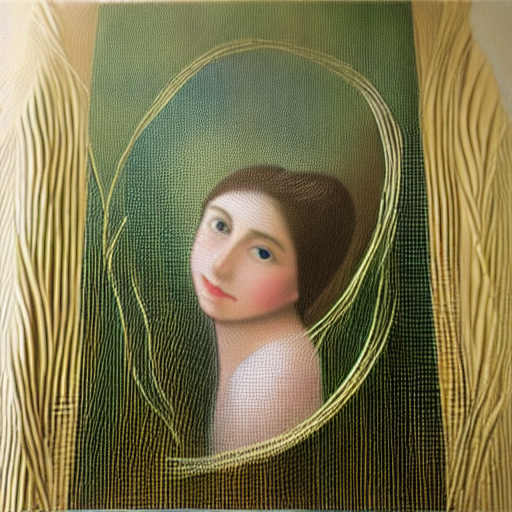

In [7]:
# Q. 프롬프트를 작성하고 하이퍼파라미터를 조절하여 이미지를 생성해 보세요. 
# 이미지를 생성합니다. 
canny_image = canny_pipe(
    prompt=("A delicate portrayal of a beautiful girl, bathed in the golden glow of enchanting sunlight, "
            "surrounded by the magic of an ethereal forest. The artwork should capture the essence of her grace, "
            "using soft pastels and earthy tones to create a dreamlike atmosphere. The artist is encouraged to infuse "
            "a poetic and ethereal style, employing high-resolution details to immerse the viewer in this fantasy realm."),
    num_inference_steps=40, 
    generator=generator, 
    image=canny_image,
    guidance_scale=7.5,
    negative_prompt=(
        "Forest fire, urban setting, artificial lighting, harsh shadows, monochromatic palette, chaotic composition, "
        "abstract interpretation, distorted features, surreal elements, minimalistic approach, low resolution, pixelation, "
        "cold atmosphere, heavy texture, unnatural colors."
    )
).images[0]



# 생성된 이미지를 저장합니다. 
canny_image.save("/aiffel/aiffel/canny_image.png")  

# 생성된 이미지를 출력합니다. 
canny_image

* 초반 이미지에서 많이 변형된 것 같지만, 프롬프트에 맞게 이미지가 생성된 것 같다.

### 인체 자세 감지
---
Openpose는 인체 자세 감지(Human pose)를 할 수 있는 전처리기이다. 자세를 감지하여 새로운 이미지를 생성해 준다.

먼저 사람의 전신이 담긴 이미지를 불러오자.

In [8]:
# controlnet-aux를 설치합니다. Human pose를 검출해주는 controlnet의 보조용 모델입니다.
!pip install controlnet-aux==0.0.1 # controlnet-aux 버전 0.0.1을 설치
                                   # ! 기호는 주피터 노트북과 같은 환경에서 터미널 명령어를 실행할 때 사용, 이 명령어는 터미널에서도 동일하게 실행

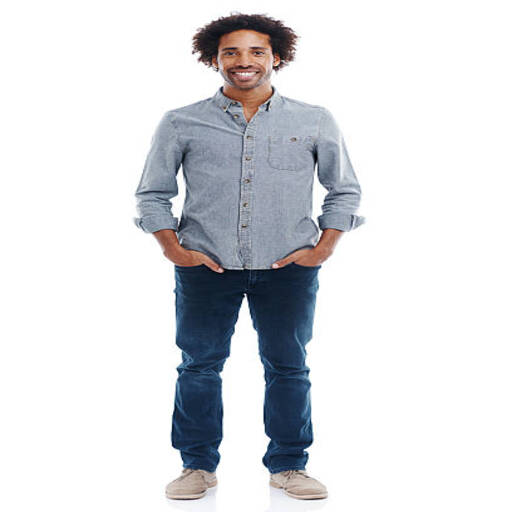

In [9]:
from diffusers.utils import load_image # diffusers 패키지의 utils 모듈에서 load_image 함수를 불러온다

openpose_image = load_image(
    "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/person.png"
)
openpose_image

Openpose 검출기를 사용하면 자세만 추출할 수 있다.

cuda


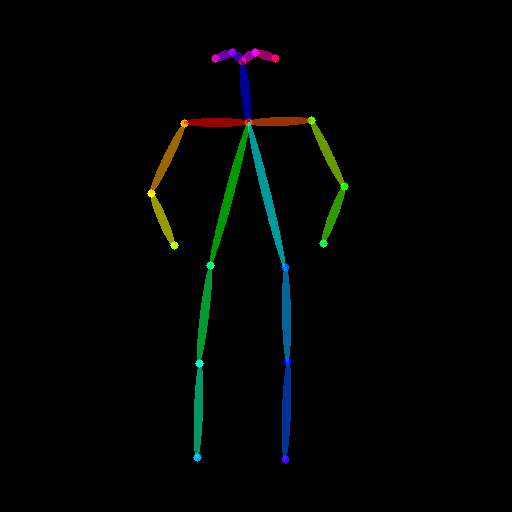

In [10]:
from controlnet_aux import OpenposeDetector # controlnet_aux 패키지에서 OpenposeDetector 클래스를 불러온다
# OpenposeDetector 클래스는 사전에 학습된 ControlNet 모델을 사용하여 인체의 자세를 검출하는 기능을 제공

# 인체의 자세를 검출하는 사전 학습된 ControlNet 불러오기
openpose = OpenposeDetector.from_pretrained("lllyasviel/ControlNet") #  OpenposeDetector 클래스의 from_pretrained 메서드를 사용하여
                                                                     # "lllyasviel/ControlNet"이라는 사전 학습된 ControlNet 모델을 불러와 openpose 변수에 할당

# 이미지에서 자세 검출
openpose_image = openpose(openpose_image) # openpose 객체를 사용하여 이미지에서 인체의 자세를 검출
                                          # openpose 객체는 함수처럼 호출되며, 이때 이미지 데이터를 인자로 전달
openpose_image

Openpose 전처리기를 사용한 모델 파이프라인을 불러온다.

In [11]:
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel 

# "lllyasviel/sd-controlnet-openpose"라는 사전 학습된 ControlNet 모델을 불러온다
openpose_controlnet = ControlNetModel.from_pretrained("lllyasviel/sd-controlnet-openpose", torch_dtype=torch.float16) # 모델이 사용할 토치(Torch)의 데이터 타입을 16비트 부동소수점 형식을 사용하도록 설정 
openpose_pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5", controlnet=openpose_controlnet, torch_dtype=torch.float16
)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

새로운 이미지를 생성해 보겠다. Canny Edge Detection에서 사용한 코드를 참고하여 여러분들이 직접 코드를 작성해 보자. 하이퍼파라미터를 조절하면 더 멋진 이미지를 생성할 수 있을 거다.

Token indices sequence length is longer than the specified maximum sequence length for this model (80 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['fantasy realm.']


  0%|          | 0/40 [00:00<?, ?it/s]

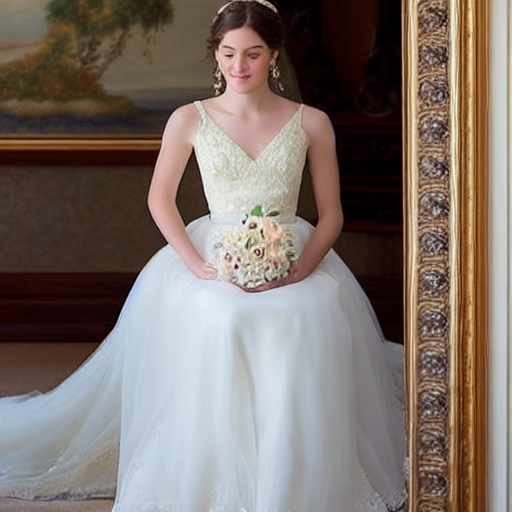

In [12]:
from diffusers import UniPCMultistepScheduler

openpose_pipe.scheduler = UniPCMultistepScheduler.from_config(openpose_pipe.scheduler.config)
openpose_pipe = openpose_pipe.to("cuda")

# Q. 코드를 작성해 보세요.
# 동일한 이미지를 생성하기 위해 seed를 넣어줍니다. 
generator = torch.manual_seed(0)

#프롬프트를 작성합니다. 
prompt = ("A delicate portrayal of a beautiful girl, bathed in the golden glow of enchanting sunlight, "
            "surrounded by the magic of an ethereal forest. The artwork should capture the essence of her grace, "
            "using soft pastels and earthy tones to create a dreamlike atmosphere. The artist is encouraged to infuse "
            "a poetic and ethereal style, employing high-resolution details to immerse the viewer in this fantasy realm.")
negative_prompt = ("Forest fire, urban setting, artificial lighting, harsh shadows, monochromatic palette, chaotic composition, "
                    "abstract interpretation, distorted features, surreal elements, minimalistic approach, low resolution, pixelation, "
                    "cold atmosphere, heavy texture, unnatural colors.")

images = openpose_image

# 이미지를 생성합니다. 
openpose_image1 = openpose_pipe(prompt=prompt,
                                num_inference_steps=40, 
                                generator=generator, 
                                image=images,
                                guidance_scale=7.5,
                                negative_prompt=negative_prompt).images[0]

# 생성된 이미지를 저장합니다. 
openpose_image1.save("/aiffel/aiffel/canny_image.png")

# 생성된 이미지를 출력합니다. 
openpose_image1

* 아쉽게도 이미지 속 주인공의 얼굴이 조금 일그러진 것을 볼 수 있다.(무섭다.. ㅠ)
* 팔 부분은 포즈가 반영이된 것 같으나, 이미지 속 주인공은 앉아 있는 포즈로 약간 다른 것을 확인할 수 있었다.

  0%|          | 0/40 [00:00<?, ?it/s]

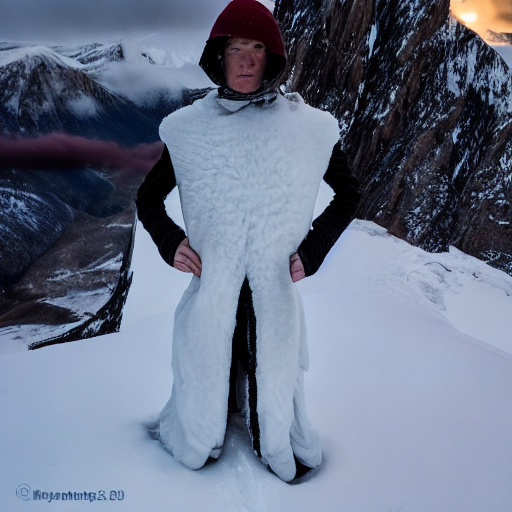

In [13]:
# Q. 프롬프트를 작성하고 하이퍼파라미터를 조절하여 이미지를 생성해 보세요. 
# 동일한 이미지를 생성하기 위해 seed를 넣어줍니다. 
generator = torch.manual_seed(0)

#프롬프트를 작성합니다. 
prompt = ("under alpenglow's embrace, a lone soul stands amidst towering peaks, "
           "wind-whispered grass of gold swaying, silhouette etched against dawn's ethereal canvas, "
           "majestic snow crowns the heights, a contemplative posture graced by solitude and grandeur, "
           "Max Rive's essence in the landscape's details, every strand of mountainous terrain a dance of shadows and light.")
negative_prompt = ("avoid crowded chaos, harsh and lifeless lighting, misshapen mountains, distorted perspective, "
                   "unnatural colors, lack of depth, haphazard detailing, pixelation, unnatural blending, "
                   "over-saturation, jagged edges, serenity's absence, a poor execution of majestic ambiance.")

images = openpose_image

# 이미지를 생성합니다. 
openpose_image2 = openpose_pipe(prompt=prompt,
                                controlnet_conditioning_scale=1.0,
                                num_inference_steps=40, 
                                generator=generator, 
                                image=images,
                                guidance_scale=7.5,
                                negative_prompt=negative_prompt).images[0]

# 생성된 이미지를 저장합니다. 
openpose_image2.save("/aiffel/aiffel/canny_image.png")

# 생성된 이미지를 출력합니다. 
openpose_image2

* 포즈는 잘 반영된 것 같지만, 얼굴이 또 일그리진 것을 확인할 수 있다.

### 윤곽선 검출 + 인체 자세 감지
---
이번에는 위에서 실습한 2가지의 전처리기를 동시에 사용해 보자. 2개의 전처리기를 controlnets라는 리스트로 만들어 파이프라인으로 전달하면 된다.

#### Canny 알고리즘을 사용한 윤곽선 검출

먼저 Canny 알고리즘으로 윤곽선을 검출한다. Canny 알고리즘으로 윤곽선을 검출한 이미지 위에 인체 자세 검출 전처리기를 올려줄 것이기 때문에 인체 자세를 넣어줄 부분을 이미지 내에서 지워주어야 한다는 점을 주의하자.

직접 아래의 코드를 작성해 보자.

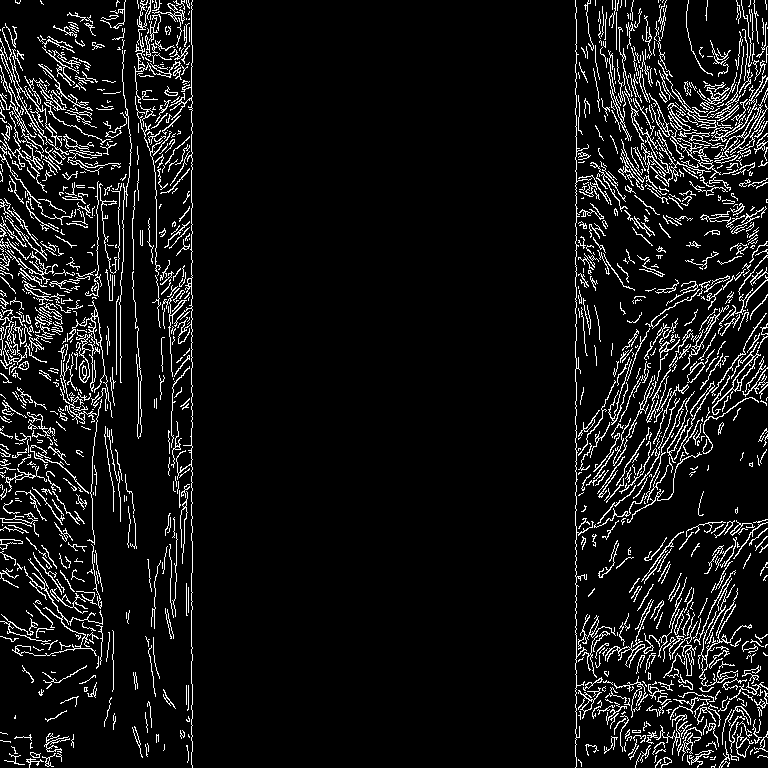

In [14]:
from diffusers.utils import load_image # diffusers.utils 모듈에서 load_image 함수를 가져옴
from PIL import Image # PIL은 Python Imaging Library로 이미지 처리에 사용
import cv2 # cv2는 OpenCV 패키지로 컴퓨터 비전 작업을 위해 사용됨
import numpy as np # numpy는 수치 계산을 위한 라이브러리
from diffusers.utils import load_image # 중복된 걸 나중에 알았다.. 큰 문제 없으니 두는 걸로..

# Q. 코드를 작성해 보세요.
# 이미지를 불러오세요. 
canny_image = load_image(
    "https://ichef.bbci.co.uk/news/800/cpsprodpb/7b05/live/eaf2b270-0cb2-11ee-9e94-25f17ea6acca.png")

# 원하는 리사이즈 크기를 지정합니다.
desired_size = (768, 768)

# 이미지를 리사이즈합니다.
canny_image = canny_image.resize(desired_size)

#threshhold를 지정합니다. 
low_threshold = 100 # Canny 에지 검출을 위한 threshold 값인 low_threshold와 high_threshold를 설정
high_threshold = 200

# 이미지를 NumPy 배열로 변환합니다. 
canny_image = np.array(canny_image)

# 인체 감지 포즈를 넣어줄 가운데 부분을 지워줍니다. 
zero_start = canny_image.shape[1] // 4 # zero_start 변수는 이미지의 너비(가로)를 4로 나눈 값을 저장합니다. 이는 이미지 가로의 1/4 지점을 나타낸다
zero_end = zero_start + canny_image.shape[1] // 2 # zero_end 변수는 zero_start에 이미지의 너비를 2로 나눈 값을 더한 값으로 설정,
                                                  # 이는 가운데 부분의 끝을 나타냄
                                                  # 따라서 zero_start에서 시작해서 가로의 1/2 지점까지가 가운데 부분
canny_image[:, zero_start:zero_end] = 0 # 이미지의 모든 행(rows)에 대해서, 가운데 부분의 열(columns)을 모두 0으로 설정, 여기서 0은 검은색을 나타냄

# 윤곽선을 검출하고 NumPy 배열을 PIL 이미지로 변환합니다. 
canny_image = cv2.Canny(canny_image, low_threshold, high_threshold)
canny_image = canny_image[:, :, None]
canny_image = np.concatenate([canny_image, canny_image, canny_image], axis=2)
canny_image = Image.fromarray(canny_image)

canny_image

#### Openpose를 사용한 인체 자세 검출

인체 자세를 검출해 준다.

In [15]:
from controlnet_aux import OpenposeDetector
from diffusers.utils import load_image 

# Q. 아래의 코드를 작성해 주세요.
# 이미지를 불러옵니다. 
openpose_image = load_image(
    "https://previews.123rf.com/images/marincas_andrei/marincas_andrei1207/marincas_andrei120700004/14284942-%EC%8A%A4%ED%8A%9C%EB%94%94%EC%98%A4%EC%97%90%EC%84%9C-%ED%8F%AC%EC%A6%88-%EC%82%AC%EB%9E%8C.jpg"
)

# OpenposeDetector를 사용하여 인체 자세를 검출합니다. 
openpose = OpenposeDetector.from_pretrained("lllyasviel/ControlNet")
openpose_image = openpose(openpose_image)

cuda


이미지 크기: (512, 768)


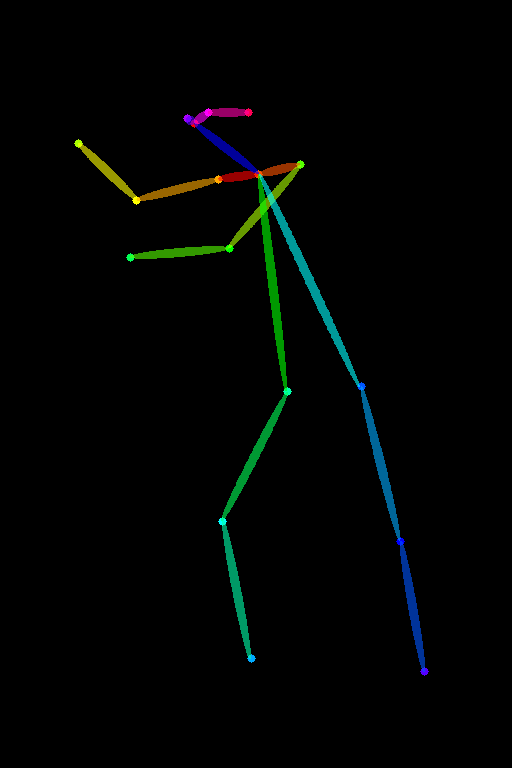

In [16]:
# 이미지 크기 확인
image_size = openpose_image.size

# 가로(width)와 세로(height) 크기 출력
print("이미지 크기:", image_size)
openpose_image

In [17]:
torch.cuda.empty_cache()

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

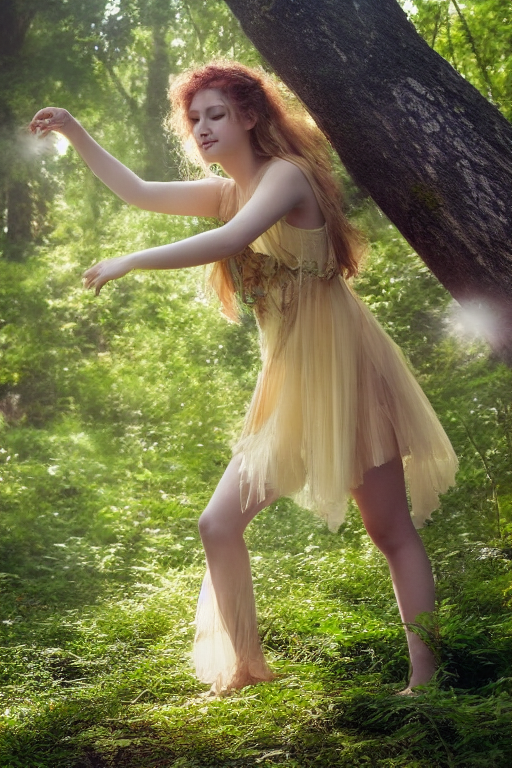

In [18]:
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler  

# Q. 코드를 작성해 보세요.
# Edge Detection과 Openpose, 2개의 전처리기를 controlnets라는 리스트로 만듭니다. 
controlnets = [openpose_controlnet, canny_controlnet]

# 리스트 controlnets를 파이프라인으로 전달합니다. 
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5", controlnet=controlnets, torch_dtype=torch.float16
)

pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
pipe = pipe.to("cuda")

# 프롬프트를 작성합니다. 
prompt = (
    "A girl gracefully weaves through a mystical green forest, bathed in dappled sunlight. "
    "The artist, a whimsical dreamer, creates an ethereal style capturing the essence of solitude and magic. "
    "Shades of green and Unreal Engine lend a painterly quality to this enchanting scene."
)
negative_prompt = (
    "Bustling city, harsh lighting, crowded spaces, detailed realism, monochrome, digital art, "
    "low resolution, busy composition."
)

# seed를 지정합니다. 
generator = torch.manual_seed(0)

images = [openpose_image, canny_image]

# 이미지를 생성합니다. 
image = pipe(prompt=prompt,
             controlnet_conditioning_scale=[1.0],
             num_inference_steps=10, 
             generator=generator, 
             image=images,
             guidance_scale=4,
             negative_prompt=negative_prompt).images[0]

# 생성된 이미지를 저장합니다.
#image.save("aiffel/aiffel/multi_controlnet_output.png")

# 생성된 이미지를 출력합니다.  
image

* 이 코드를 어떻게 구성해야 하는지 몰라서 꽤나 애먹었다.. 하지만 결과물이 출력돼서 다행이다.
* 얼굴이 좀 일그러졌는데, 그래도 포즈를 잘 잡고, 프롬프트에 맞는 이미지를 잘 생성해낸 것 같다.

#### 오픈 포즈 이미지와 윤곽선 이미지의 사이즈를 똑같이 리사이징

오픈 포즈 이미지와 윤곽선 이미지의 사이즈를 똑같이 사이즈를 줄여서 리사이징했을 때, 아래와 같은 이미지가 생성되었다.(노트북 파일에서 너무 많은 커널을 실행할 경우 메모리가 부족해지는 현상 때문에 이미지만 첨부합니다.)

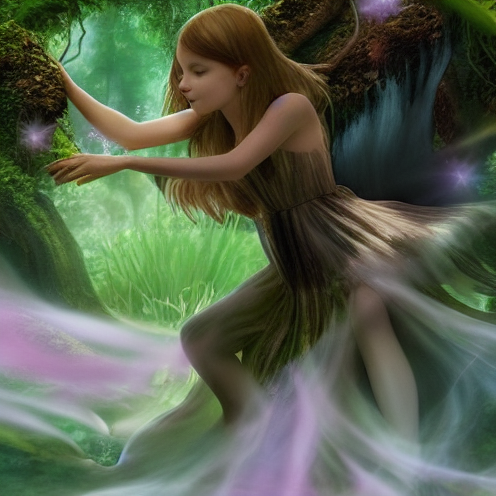

* 이미지의 퀄리티는 첫 번째 이미지보다 조금 떨어지지만, 완성도가 높고 윤곽선이 첫 번째 이미지보다 잘 반영된 것 같은 느낌이 든다.

### 회고문

쿠다 메모리가 부족해서 아주 고생했다 ㅠㅠ.. 그리고 코드를 이해하는 데도 시간이 좀 걸렸다. 진행하는 테스크도 초반에는 명확하지 않았으나, 결과물이 출력이 되니 어느 정도 이해가 되는 것 같다. 이미지를 생성하는 것은 재미가 있는데, 메모리 문제로 인내심 테스트를 좀 한 것같다.

#### K
: 어떻게든 해결하기 위해서 코드 수정을 하였다. 내 구글링 능력으로는, 이번 프로젝트는 구글링도 잘 안 됐고, GPT를 이용해서 코드를 이해하면서 오류가 난 부분을 최대한 수정하려고 노력했다. 코드를 최대한 이해하려고 했다. 메모리 부족 시, 하이퍼파라미터를 조절하면서 메모리를 덜 쓰려고 노력했다. GPT를 이용해서 프롬프트를 작성했다.

#### P
: 메모리가 부족해서 많은 시도를 해보지 못 한 게 아쉽다.

#### T
: 다른 이미지를 이용해서 시도해봐야겠다.